# 10 · What if Freddie Mac does not call? Duration of the STACR 2026-DNA1 notes

**Purpose.** Notebook 09 showed that when rates stay high, M-2A and M-2B stop at about **4.4 years**, because our pricing assumes Freddie Mac calls the deal in **February 2031**. The call hides how long the notes would really last. Prof. Wallace's question is about the **duration** of CRT notes and what it costs. So this notebook does two things:

1. **No-call run.** It removes the 2031 call and lets the notes run until the pool pays them down, or until the **scheduled maturity in February 2046** (PPM p. 7), when any remaining principal is due.
2. **Duration measures.** For every note, rate path, lock-in strength and call assumption, it computes
   - **spread duration**: how much the price moves when the note's own spread (discount margin) moves, and
   - **effective duration**: how much the price moves when *interest rates* move (mortgage rate and SOFR together), letting prepayments respond.

**Lock-in cases** (from notebook 09):
- none (0);
- **our estimate from Freddie Mac 2022-2026 data (0.025 per pp)**;
- FHFA WP 24-03 (0.20 per pp), used as a stress case.

**Rate paths:** the team base path, plus three constant paths: 6.28%, 7.28% (the rate on the valuation date) and 8.28%.

**Code used.**
- `src/duration.py` (new): extends the paths, runs the grid and computes the duration measures.
- `src/run_waterfall_pricing.run_scenario`: now has a `call_date` option. The default is unchanged (call in Feb 2031).

## 1 · Setup

**What this cell does.** Loads the September 2026 tape (the same pool as notebooks 01-09), the team's rate scenarios and the pricing rates (SOFR and day counts), and prints the key dates and the three lock-in strengths.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.2f}".format)

from src import collateral_projection as cp, lockin as lk, duration as du
from src import run_waterfall_pricing as rw

TABLES, FIGURES = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
pool = cp.load_pool()
team = cp.get_scenarios(None)
all_rates = pd.read_csv(lk.PRICING_RATES)
print(f"Pool: {len(pool):,} loans, ${pool['Current Balance'].sum()/1e9:.2f}bn")
print(f"Call date: {du.CALL_DATE.date()}  |  scheduled maturity: {du.MATURITY_DATE.date()}  |  months to maturity: {du.N_TO_MATURITY}")
print("Lock-in cases:", {k: round(v, 3) for k, v in du.DURATION_CASES.items()})

Pool: 56,433 loans, $19.25bn
Call date: 2031-02-25  |  scheduled maturity: 2046-02-25  |  months to maturity: 233
Lock-in cases: {'no lock-in': 0.0, 'lock-in (estimated)': 0.025, 'lock-in (FHFA)': 0.2}


**Result.** Same pool as before: 56,433 loans and $19.25bn. The call date is February 25, 2031. The scheduled maturity is February 25, 2046, which is 233 monthly payments from October 2026. The three lock-in strengths are 0, 0.025 (our Freddie Mac estimate) and 0.20 (FHFA).

## 2 · Extending the paths to 2046

**What this cell does.** The team's paths end at the 2031 call (53 months). Without the call we need 233 months, up to the February 2046 maturity. After month 53:
- the mortgage rate stays at its last value;
- house prices keep growing at their last-12-month pace;
- SOFR stays at its last value, with actual day counts between payment dates on the 25th.

**Why this choice.** It is the simplest neutral extension: no new view on rates after 2031. The constant-rate paths are flat throughout anyway.

**Q&A**

**Q: Doesn't the extension drive the result?**
A: Only a little. Most of a note's extension comes from how slowly the pool pays down *before* 2031. That part is unchanged. After 2031 the paths are flat, so prepayment speed stays wherever it was.

Pricing months: 233 (first 2026-10-25, last 2046-02-25)
SOFR at the call: 3.42%, held flat after it


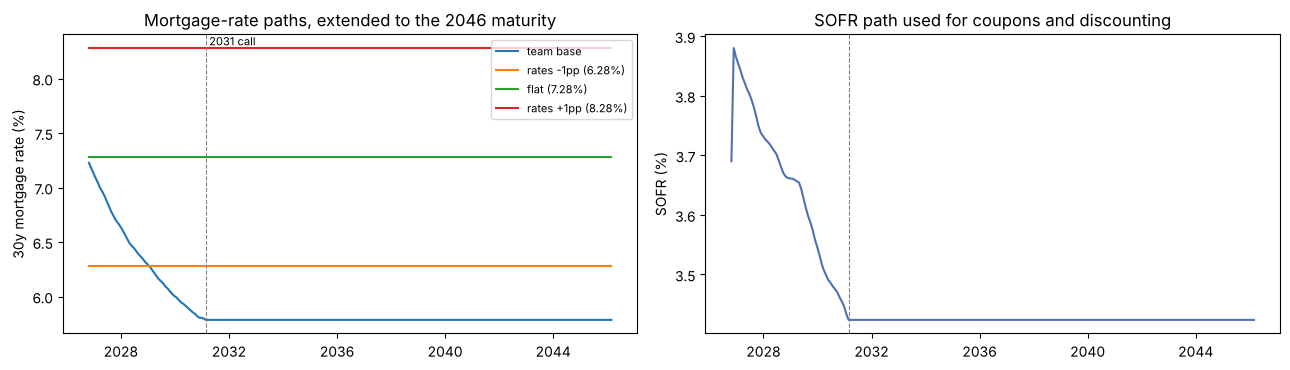

In [2]:
rates = du.extend_rates(all_rates[all_rates.scenario == "base"])
const = lk.constant_rate_paths(team["base"]["hpi"], {"rates -1pp (6.28%)": 6.28, "flat (7.28%)": 7.28, "rates +1pp (8.28%)": 8.28})
paths = {"team base": du.extend_path(team["base"]), **{k: du.extend_path(v) for k, v in const.items()}}
ORDER = list(paths)

print(f"Pricing months: {len(rates)} (first {rates.date.iloc[0].date()}, last {rates.date.iloc[-1].date()})")
print(f"SOFR at the call: {rates.sofr_coupon_decimal.iloc[52]:.2%}, held flat after it")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, p in paths.items():
    ax[0].plot(rates.date, p["rate"], label=name)
ax[0].axvline(du.CALL_DATE, color="grey", ls="--", lw=0.8); ax[0].text(du.CALL_DATE, ax[0].get_ylim()[1], " 2031 call", va="top", fontsize=8)
ax[0].set_ylabel("30y mortgage rate (%)"); ax[0].set_title("Mortgage-rate paths, extended to the 2046 maturity"); ax[0].legend(fontsize=8)
ax[1].plot(rates.date, rates.sofr_coupon_decimal * 100, color="#4C72B0")
ax[1].axvline(du.CALL_DATE, color="grey", ls="--", lw=0.8)
ax[1].set_ylabel("SOFR (%)"); ax[1].set_title("SOFR path used for coupons and discounting")
plt.tight_layout(); fig.savefig(FIGURES / "10_1_extended_paths.png", dpi=150); plt.show()

**Result.** The pricing rates now run for 233 months, from October 2026 to February 2046. SOFR is 3.42% at the call and stays there afterwards. The team base mortgage rate ends at 5.79% and stays there. The three constant paths stay at 6.28%, 7.28% and 8.28% the whole time.

## 3 · WALs with and without the call

**What this cell does.** Runs every combination of 4 rate paths × 3 lock-in strengths × 2 call assumptions. For each one it projects the pool, runs the waterfall and prices the notes. It also projects the pool with rates 25 bp higher and 25 bp lower, which section 6 needs. It saves everything to `outputs/tables/duration_grid.csv` and shows the WAL table.

**How to read the table.** Rows are rate path and note. Columns are call assumption, then lock-in case. Compare the "call 2031" block with the "no call" block for the same lock-in case.

In [3]:
grid = du.run_grid(pool, paths, {k: rates for k in paths})
grid.to_csv(TABLES / "duration_grid.csv", index=False)

def table(value, paths_=ORDER):
    t = grid.pivot_table(index=["path", "tranche"], columns=["call", "lockin_case"], values=value)
    cols = [(c, l) for c in du.CALL_CASES for l in du.DURATION_CASES]
    return t.loc[paths_, cols]

wal = table("wal_years")
wal.to_csv(TABLES / "duration_wal_call_vs_no_call.csv")
display(wal.rename_axis(["rate path", "WAL (years)"]))

call                            call 2031                                     \
lockin_case                    no lock-in lock-in (estimated) lock-in (FHFA)   
rate path          WAL (years)                                                 
team base          A-1               1.40                1.40           1.40   
                   M-1               1.20                1.20           1.22   
                   M-2A              2.43                2.43           2.45   
                   M-2B              2.82                2.82           2.84   
rates -1pp (6.28%) A-1               1.40                1.40           1.40   
                   M-1               0.61                0.61           0.61   
                   M-2A              1.57                1.57           1.58   
                   M-2B              2.07                2.08           2.08   
flat (7.28%)       A-1               1.40                1.40           1.40   
                   M-1               1.88                1.91           2.04   
                   M-2A              4.31                4.33           4.40   
                   M-2B              4.40                4.40           4.40   
rates +1pp (8.28%) A-1               1.40                1.40           1.40   
                   M-1               2.59                2.66           3.07   
                   M-2A              4.40                4.40           4.40   
                   M-2B              4.40                4.40           4.40   

call                              no call                                     
lockin_case                    no lock-in lock-in (estimated) lock-in (FHFA)  
rate path          WAL (years)                                                
team base          A-1               1.40                1.40           1.40  
                   M-1               1.20                1.20           1.22  
                   M-2A              2.43                2.43           2.45  
                   M-2B              2.82                2.82           2.84  
rates -1pp (6.28%) A-1               1.40                1.40           1.40  
                   M-1               0.61                0.61           0.61  
                   M-2A              1.57                1.57           1.58  
                   M-2B              2.07                2.08           2.08  
flat (7.28%)       A-1               1.40                1.40           1.40  
                   M-1               1.88                1.91           2.04  
                   M-2A              4.49                4.54           4.86  
                   M-2B              5.60                5.66           6.05  
rates +1pp (8.28%) A-1               1.40                1.40           1.40  
                   M-1               2.69                2.79           3.55  
                   M-2A              6.07                6.26           7.66  
                   M-2B              7.40                7.64           9.22

**Result.** **The call matters far more than lock-in.** On falling or low rates (the team base path and 6.28%), nothing changes, because every note is repaid well before 2031. On high rates the call was hiding a lot:

| path | note | WAL with call | WAL without call (none / estimated / FHFA lock-in) |
|---|---|---|---|
| flat 7.28% | M-2A | 4.31-4.40 | 4.49 / 4.54 / 4.86 |
| flat 7.28% | M-2B | 4.40 | **5.60 / 5.66 / 6.05** |
| +1 pp (8.28%) | M-1 | 2.59-3.07 | 2.69 / 2.79 / 3.55 |
| +1 pp (8.28%) | M-2A | 4.40 | 6.07 / 6.26 / 7.66 |
| +1 pp (8.28%) | M-2B | 4.40 | **7.40 / 7.64 / 9.22** |

So without the call, M-2B's life can be **7.4 years** at 8.28% even with no lock-in. With FHFA-strength lock-in it reaches **9.2 years**, more than double the 4.4 years we see with the call. **Lock-in matters much more once the call is removed.** At +1 pp, FHFA lock-in adds 1.8 years to M-2B without the call, but nothing with it. With our estimated strength it adds about 0.24 years.

## 4 · How long M-2B stays outstanding

**What this cell does.** Plots M-2B's remaining balance month by month on the +1 pp path, for each lock-in case, with the call (left) and without it (right). It then shows, for every note and path, how many extra years of WAL come from removing the call.

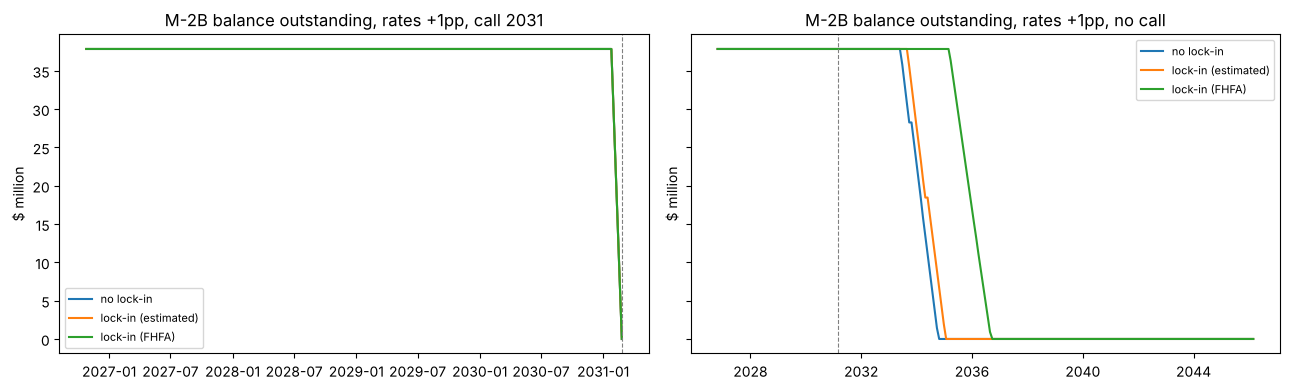

lockin_case                                            no lock-in  \
rate path          extra WAL without the call (years)               
team base          A-1                                       0.00   
                   M-1                                       0.00   
                   M-2A                                      0.00   
                   M-2B                                      0.00   
rates -1pp (6.28%) A-1                                       0.00   
                   M-1                                       0.00   
                   M-2A                                      0.00   
                   M-2B                                      0.00   
flat (7.28%)       A-1                                       0.00   
                   M-1                                       0.00   
                   M-2A                                      0.18   
                   M-2B                                      1.20   
rates +1pp (8.28%) A-1                                       0.00   
                   M-1                                       0.09   
                   M-2A                                      1.67   
                   M-2B                                      3.00   

lockin_case                                            lock-in (estimated)  \
rate path          extra WAL without the call (years)                        
team base          A-1                                                0.00   
                   M-1                                                0.00   
                   M-2A                                               0.00   
                   M-2B                                               0.00   
rates -1pp (6.28%) A-1                                                0.00   
                   M-1                                                0.00   
                   M-2A                                               0.00   
                   M-2B                                               0.00   
flat (7.28%)       A-1                                                0.00   
                   M-1                                                0.00   
                   M-2A                                               0.21   
                   M-2B                                               1.26   
rates +1pp (8.28%) A-1                                                0.00   
                   M-1                                                0.13   
                   M-2A                                               1.86   
                   M-2B                                               3.24   

lockin_case                                            lock-in (FHFA)  
rate path          extra WAL without the call (years)                  
team base          A-1                                           0.00  
                   M-1                                           0.00  
                   M-2A                                          0.00  
                   M-2B                                          0.00  
rates -1pp (6.28%) A-1                                           0.00  
                   M-1                                           0.00  
                   M-2A                                          0.00  
                   M-2B                                          0.00  
flat (7.28%)       A-1                                           0.00  
                   M-1                                          -0.00  
                   M-2A                                          0.47  
                   M-2B                                          1.65  
rates +1pp (8.28%) A-1                                           0.00  
                   M-1                                           0.48  
                   M-2A                                          3.26  
                   M-2B                                          4.82

In [4]:
# principal paid to M-2B each month, +1pp path, call vs. no call, for each lock-in case
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for k, (cname, cdate) in enumerate(du.CALL_CASES.items()):
    for lname, g in du.DURATION_CASES.items():
        cf = lk.project(pool, paths["rates +1pp (8.28%)"]["hpi"], paths["rates +1pp (8.28%)"]["rate"], g)
        flows, _ = rw.run_scenario(cf, rates, call_date=cdate)
        f = flows[flows.tranche == "M-2B"]
        ax[k].plot(f["date"], f["ending_balance"] / 1e6, label=lname)
    ax[k].axvline(du.CALL_DATE, color="grey", ls="--", lw=0.8)
    ax[k].set_title(f"M-2B balance outstanding, rates +1pp, {cname}"); ax[k].set_ylabel("$ million"); ax[k].legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIGURES / "10_2_m2b_balance_call_vs_no_call.png", dpi=150); plt.show()

ext = (grid[grid.call == "no call"].set_index(["path", "tranche", "lockin_case"])["wal_years"]
       - grid[grid.call == "call 2031"].set_index(["path", "tranche", "lockin_case"])["wal_years"])
display(ext.unstack("lockin_case")[list(du.DURATION_CASES)].loc[ORDER]
        .rename_axis(["rate path", "extra WAL without the call (years)"]))

**Result.** With the call (left), every high-rate case ends abruptly in February 2031: Freddie Mac pays off whatever is left. Without the call (right), M-2B pays down slowly. Its last payment comes in month 97 with no lock-in, month 100 with our estimate, and month 120 (September 2036) with FHFA lock-in.

The extension table puts numbers on this. Removing the call adds **3.0 years** to M-2B's WAL at +1 pp with no lock-in, 3.2 years with our estimate and **4.8 years** with FHFA lock-in. On the flat path it adds 1.2-1.65 years. M-1 and A-1 barely change, because they are mostly repaid before 2031.

**What this means.** The call is a valuable option for investors only if Freddie Mac exercises it. Our earlier "4.4 years" assumes it always does. Freddie Mac is not required to call, and in a high-rate world the outstanding notes may be cheap funding for it, so the no-call case is a real risk for M-2 holders.

## 5 · Spread duration

**What this cell does.** For each case it solves the discount margin (DM) that matches the Bloomberg ask price. It then reprices the same cash flows at DM ± 25 bp:

spread duration = (P(DM − 25bp) − P(DM + 25bp)) / (2 × P × 0.0025)

**Why it matters.** For a floating-rate note, the coupon resets with SOFR, so ordinary interest-rate risk is small. The main market risk is that **credit spreads widen**. Spread duration measures that risk: a spread duration of 4 means the price falls about 4% if the note's spread widens by 1 percentage point. It is roughly the note's discounted life. So anything that lengthens the note (slower prepayment, lock-in, no call) raises the investor's exposure to spread risk.

call                                call 2031                      \
lockin_case                        no lock-in lock-in (estimated)   
rate path          spread duration                                  
team base          A-1                   1.35                1.35   
                   M-1                   1.16                1.17   
                   M-2A                  2.31                2.31   
                   M-2B                  2.65                2.65   
rates -1pp (6.28%) A-1                   1.35                1.35   
                   M-1                   0.61                0.61   
                   M-2A                  1.52                1.52   
                   M-2B                  1.99                1.99   
flat (7.28%)       A-1                   1.35                1.35   
                   M-1                   1.79                1.81   
                   M-2A                  3.91                3.93   
                   M-2B                  3.98                3.98   
rates +1pp (8.28%) A-1                   1.35                1.35   
                   M-1                   2.42                2.47   
                   M-2A                  3.98                3.98   
                   M-2B                  3.98                3.98   

call                                                 no call  \
lockin_case                        lock-in (FHFA) no lock-in   
rate path          spread duration                             
team base          A-1                       1.35       1.35   
                   M-1                       1.19       1.16   
                   M-2A                      2.33       2.31   
                   M-2B                      2.67       2.65   
rates -1pp (6.28%) A-1                       1.35       1.35   
                   M-1                       0.61       0.61   
                   M-2A                      1.53       1.52   
                   M-2B                      1.99       1.99   
flat (7.28%)       A-1                       1.35       1.35   
                   M-1                       1.93       1.79   
                   M-2A                      3.98       4.05   
                   M-2B                      3.98       4.93   
rates +1pp (8.28%) A-1                       1.35       1.35   
                   M-1                       2.84       2.49   
                   M-2A                      3.98       5.28   
                   M-2B                      3.98       6.24   

call                                                                   
lockin_case                        lock-in (estimated) lock-in (FHFA)  
rate path          spread duration                                     
team base          A-1                            1.35           1.35  
                   M-1                            1.17           1.19  
                   M-2A                           2.31           2.33  
                   M-2B                           2.65           2.67  
rates -1pp (6.28%) A-1                            1.35           1.35  
                   M-1                            0.61           0.61  
                   M-2A                           1.52           1.53  
                   M-2B                           1.99           1.99  
flat (7.28%)       A-1                            1.35           1.35  
                   M-1                            1.81           1.93  
                   M-2A                           4.10           4.35  
                   M-2B                           4.97           5.27  
rates +1pp (8.28%) A-1                            1.35           1.35  
                   M-1                            2.58           3.22  
                   M-2A                           5.42           6.43  
                   M-2B                           6.41           7.46

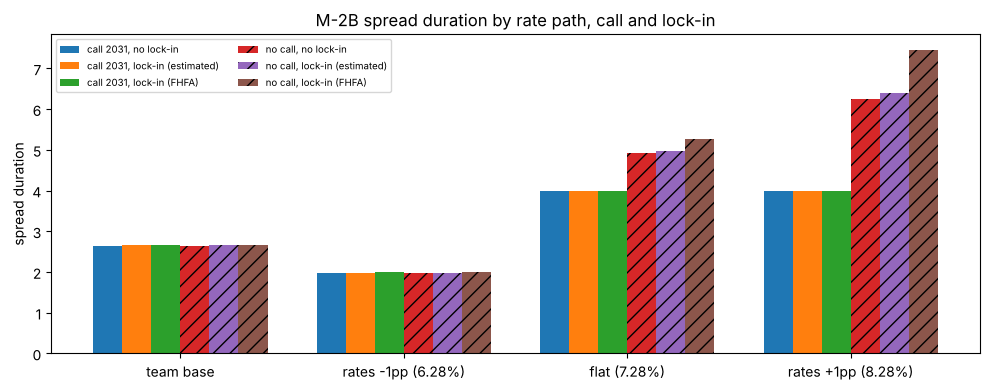

In [5]:
sd = table("spread_duration")
sd.to_csv(TABLES / "duration_spread.csv")
display(sd.rename_axis(["rate path", "spread duration"]))

m2b = grid[grid.tranche == "M-2B"]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ORDER)); w = 0.13
for j, (cname, lname) in enumerate([(c, l) for c in du.CALL_CASES for l in du.DURATION_CASES]):
    s = m2b[(m2b.call == cname) & (m2b.lockin_case == lname)].set_index("path").loc[ORDER, "spread_duration"]
    ax.bar(x + (j - 2.5) * w, s, w, label=f"{cname}, {lname}", hatch="" if cname == "call 2031" else "//")
ax.set_xticks(x, ORDER); ax.set_ylabel("spread duration"); ax.set_title("M-2B spread duration by rate path, call and lock-in")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); fig.savefig(FIGURES / "10_3_m2b_spread_duration.png", dpi=150); plt.show()

**Result.** Spread duration tracks the note's life:
- **Team base path:** A-1 1.35, M-1 1.16, M-2A 2.31, M-2B 2.65.
- **High rates, with the call:** M-2A and M-2B are capped at about **3.98**.
- **High rates, without the call:** M-2B is **4.93-5.27** on the flat path and **6.24 / 6.41 / 7.46** at +1 pp (none / estimated / FHFA lock-in).

**What this means.** Without the call, M-2B's spread risk at +1 pp is about 57% higher than with it (6.24 vs. 3.98), and FHFA-strength lock-in adds another 1.2. So the investor's exposure to credit-spread widening depends mainly on the rate path and the call, with lock-in as an amplifier. This is the "duration" of CRT notes that matters for their price.

## 6 · Effective duration and how WAL responds to rates

**What this cell does.** It moves the mortgage-rate path **and** SOFR up and down by 25 bp, re-projects the pool so prepayments respond, and reprices at the same DM:

effective duration = (P(rates − 25bp) − P(rates + 25bp)) / (2 × P × 0.0025)

It also reports how much the WAL changes for a 100 bp rise in rates (from the same ±25 bp runs).

**What to expect.** A floater priced exactly at par has no rate duration even if its life changes. A note priced **below par** (DM above its coupon spread, like M-2A and M-2B) loses value when it extends, because the investor earns the below-market coupon spread for longer. So the effective duration of a discount CRT note is roughly (DM − coupon spread) × (how much its life extends when rates rise). That makes it a direct measure of **extension risk**.

In [6]:
ed = table("effective_duration")
ed.to_csv(TABLES / "duration_effective.csv")
display(ed.rename_axis(["rate path", "effective duration"]))

sens = grid.assign(wal_change_per_100bp=(grid.wal_up_years - grid.wal_down_years) / (2 * du.SHIFT_BPS / 100))
s = sens.pivot_table(index=["path", "tranche"], columns=["call", "lockin_case"], values="wal_change_per_100bp")
s = s.loc[ORDER, [(c, l) for c in du.CALL_CASES for l in du.DURATION_CASES]]
s.to_csv(TABLES / "duration_wal_sensitivity.csv")
display(s.rename_axis(["rate path", "WAL change per +100bp (years)"]))

call                                   call 2031                      \
lockin_case                           no lock-in lock-in (estimated)   
rate path          effective duration                                  
team base          A-1                     -0.02               -0.02   
                   M-1                     -0.04               -0.04   
                   M-2A                     0.16                0.16   
                   M-2B                     0.51                0.51   
rates -1pp (6.28%) A-1                     -0.02               -0.02   
                   M-1                     -0.05               -0.05   
                   M-2A                     0.28                0.28   
                   M-2B                     0.92                0.93   
flat (7.28%)       A-1                     -0.02               -0.02   
                   M-1                     -0.04               -0.04   
                   M-2A                     0.05                0.05   
                   M-2B                    -0.03               -0.03   
rates +1pp (8.28%) A-1                     -0.02               -0.02   
                   M-1                     -0.02               -0.02   
                   M-2A                    -0.03               -0.03   
                   M-2B                    -0.04               -0.04   

call                                                    no call  \
lockin_case                           lock-in (FHFA) no lock-in   
rate path          effective duration                             
team base          A-1                         -0.02      -0.02   
                   M-1                         -0.04      -0.04   
                   M-2A                         0.17       0.16   
                   M-2B                         0.52       0.51   
rates -1pp (6.28%) A-1                         -0.02      -0.02   
                   M-1                         -0.06      -0.05   
                   M-2A                         0.29       0.28   
                   M-2B                         0.94       0.92   
flat (7.28%)       A-1                         -0.02      -0.02   
                   M-1                         -0.04      -0.04   
                   M-2A                         0.03       0.13   
                   M-2B                        -0.04       0.40   
rates +1pp (8.28%) A-1                         -0.02      -0.02   
                   M-1                         -0.03      -0.02   
                   M-2A                        -0.03      -0.01   
                   M-2B                        -0.04       0.01   

call                                                                      
lockin_case                           lock-in (estimated) lock-in (FHFA)  
rate path          effective duration                                     
team base          A-1                              -0.02          -0.02  
                   M-1                              -0.04          -0.04  
                   M-2A                              0.16           0.17  
                   M-2B                              0.51           0.52  
rates -1pp (6.28%) A-1                              -0.02          -0.02  
                   M-1                              -0.05          -0.06  
                   M-2A                              0.28           0.29  
                   M-2B                              0.93           0.94  
flat (7.28%)       A-1                              -0.02          -0.02  
                   M-1                              -0.04          -0.04  
                   M-2A                              0.13           0.16  
                   M-2B                              0.41           0.48  
rates +1pp (8.28%) A-1                              -0.02          -0.02  
                   M-1                              -0.02          -0.03  
                   M-2A                             -0.00           0.02  
       

call                                              call 2031  \
lockin_case                                      no lock-in   
rate path          WAL change per +100bp (years)              
team base          A-1                                 0.00   
                   M-1                                 0.92   
                   M-2A                                1.71   
                   M-2B                                1.93   
rates -1pp (6.28%) A-1                                 0.00   
                   M-1                                 0.77   
                   M-2A                                1.80   
                   M-2B                                2.46   
flat (7.28%)       A-1                                 0.00   
                   M-1                                 1.37   
                   M-2A                                1.38   
                   M-2B                                0.06   
rates +1pp (8.28%) A-1                                 0.00   
                   M-1                                 0.20   
                   M-2A                                0.00   
                   M-2B                                0.00   

call                                                                  \
lockin_case                                      lock-in (estimated)   
rate path          WAL change per +100bp (years)                       
team base          A-1                                          0.00   
                   M-1                                          0.93   
                   M-2A                                         1.74   
                   M-2B                                         1.95   
rates -1pp (6.28%) A-1                                          0.00   
                   M-1                                          0.77   
                   M-2A                                         1.80   
                   M-2B                                         2.47   
flat (7.28%)       A-1                                          0.00   
                   M-1                                          1.42   
                   M-2A                                         1.34   
                   M-2B                                         0.04   
rates +1pp (8.28%) A-1                                          0.00   
                   M-1                                          0.25   
                   M-2A                                         0.00   
                   M-2B                                         0.00   

call                                                               no call  \
lockin_case                                      lock-in (FHFA) no lock-in   
rate path          WAL change per +100bp (years)                             
team base          A-1                                     0.00       0.00   
                   M-1                                     1.01       0.92   
                   M-2A                                    1.82       1.71   
                   M-2B                                    1.99       1.93   
rates -1pp (6.28%) A-1                                     0.00       0.00   
                   M-1                                     0.78       0.77   
                   M-2A                                    1.83       1.80   
                   M-2B                                    2.52       2.46   
flat (7.28%)       A-1                                     0.00       0.00   
                   M-1                                     1.76       1.38   
                   M-2A                                    1.02       2.82   
                   M-2B                                    0.00       3.33   
rates +1pp (8.28%) A-1                                     0.00       0.00   
                   M-1                                     0.48       0.28   
                   M-2A                                    0.00       0.56   
                   M-2B      

**Result.** As expected for floating-rate notes, **effective (interest-rate) durations are small**, between about −0.06 and +0.94. A fixed-rate bond with a similar life would have a duration of 2-7. The pattern is informative, though:
- **M-2B has the largest rate duration:** 0.51 on the team base path and 0.92 at 6.28%. It trades below par (99.148), so when higher rates slow prepayment and extend it, the investor earns its below-market 130 bp coupon spread for longer and the price falls.
- **On high-rate paths with the call, rate duration is about 0**, because the call fixes the end date and higher rates can't extend the note further. Without the call it comes back (M-2B 0.40 on the flat path).
- **M-1 and A-1 are slightly negative** because they trade at or above par.

The WAL sensitivity table shows the extension risk directly. On the team base path, a 100 bp rise in rates extends M-2B by about **1.9 years** and M-2A by 1.7 years. On the flat path without the call, M-2B extends by **3.3 years** per 100 bp with no lock-in, and by 4.4 years with FHFA lock-in.

**What this means.** For CRT notes, rate risk shows up as **extension risk**, not price risk. Its cost to the investor depends on how far the note trades from par.

## 7 · Discount margin at the ask, with and without the call

**What this cell does.** It shows the DM an investor earns by buying at the Bloomberg ask, under each assumption.

**Why it matters.** If the market priced M-2B assuming no call, the DM it earns would differ from what we computed with the call. Comparing these with the Bloomberg ask DMs shows which assumption the market price is closer to.

In [7]:
dm = table("dm_at_ask_bps")
dm.to_csv(TABLES / "duration_dm_at_ask.csv")
display(dm.rename_axis(["rate path", "DM at Bloomberg ask (bp)"]))
print("Bloomberg ask DMs (Oct 2, 2026): A-1 87, M-1 98, M-2A 141, M-2B 157 bp")

call                                         call 2031                      \
lockin_case                                 no lock-in lock-in (estimated)   
rate path          DM at Bloomberg ask (bp)                                  
team base          A-1                           86.63               86.63   
                   M-1                           97.68               97.69   
                   M-2A                         142.14              142.13   
                   M-2B                         162.24              162.21   
rates -1pp (6.28%) A-1                           86.63               86.63   
                   M-1                           95.55               95.56   
                   M-2A                         148.38              148.37   
                   M-2B                         173.01              172.99   
flat (7.28%)       A-1                           86.63               86.63   
                   M-1                           98.49               98.51   
                   M-2A                         137.17              137.13   
                   M-2B                         151.46              151.46   
rates +1pp (8.28%) A-1                           86.63               86.63   
                   M-1                           98.88               98.91   
                   M-2A                         137.03              137.03   
                   M-2B                         151.46              151.46   

call                                                          no call  \
lockin_case                                 lock-in (FHFA) no lock-in   
rate path          DM at Bloomberg ask (bp)                             
team base          A-1                               86.63      86.63   
                   M-1                               97.73      97.68   
                   M-2A                             142.02     142.14   
                   M-2B                             162.00     162.24   
rates -1pp (6.28%) A-1                               86.63      86.63   
                   M-1                               95.57      95.55   
                   M-2A                             148.33     148.38   
                   M-2B                             172.85     173.01   
flat (7.28%)       A-1                               86.63      86.63   
                   M-1                               98.60      98.49   
                   M-2A                             137.03     136.91   
                   M-2B                             151.46     147.34   
rates +1pp (8.28%) A-1                               86.63      86.63   
                   M-1                               99.05      98.92   
                   M-2A                             137.03     135.30   
                   M-2B                             151.46     143.68   

call                                                                            
lockin_case                                 lock-in (estimated) lock-in (FHFA)  
rate path          DM at Bloomberg ask (bp)                                     
team base          A-1                                    86.63          86.63  
                   M-1                                    97.69          97.73  
                   M-2A                                  142.13         142.02  
                   M-2B                                  162.21         162.00  
rates -1pp (6.28%) A-1                                    86.63          86.63  
                   M-1                                    95.56          95.57  
                   M-2A                                  148.37         148.33  
                   M-2B                                  172.99         172.85  
flat (7.28%)       A-1                                    86.63          86.63  
                   M-1                                    98.51          98.60  
                   M-2A                                  136.84         136.

Bloomberg ask DMs (Oct 2, 2026): A-1 87, M-1 98, M-2A 141, M-2B 157 bp


**Result.** With the call, the DM earned at the ask hardly depends on lock-in (M-2B: 162 bp in the base case, 151 bp on high-rate paths). Without the call on high-rate paths, the DM at the ask is **lower**: M-2B earns 147 bp on the flat path and **144 bp at +1 pp**, compared with 151 bp with the call. M-2A earns 135-137 bp. A note bought below par earns its discount more slowly when it lasts longer.

**Compared with Bloomberg** (M-2A 141 bp, M-2B 157 bp), the ask DM lies between our base-case value and the high-rate values. The market price is consistent with an expected life between the falling-rate base case and a high-rate world. It does not need a strong lock-in assumption to explain it.

## Conclusion

1. **The 2031 call is the biggest driver of M-2's duration.** On high-rate paths, removing it extends M-2B from 4.4 years to **5.6-7.4 years** with no lock-in, and up to **9.2 years** with FHFA-strength lock-in.
2. **Lock-in matters mainly when the call is not exercised.** With the call, lock-in changes M-2 WALs by at most 0.1 years. Without it, FHFA-strength lock-in adds up to 1.8 years at +1 pp, against about 0.24 years with our Freddie-estimated strength (0.025).
3. **For these floating-rate notes, the relevant duration is spread duration.** M-2B's spread duration is 2.65 in the base case, about 4.0 with the call in high-rate cases, and **6.2-7.5 without it**. Interest-rate (effective) duration is small (under 1) and appears only as extension risk on notes priced below par.
4. **Extension risk is large on falling-to-flat paths.** On the team base path, a 100 bp rise extends M-2B by about 1.9 years.

**For the paper and the meeting with Prof. Wallace.** The duration of CRT notes is driven by the rate path and by whether Freddie Mac calls. Lock-in amplifies the no-call extension. So a natural research question is: how much is the call worth to investors, and what does extension cost Freddie Mac when rates stay high?

**Next steps.**
- (a) Value the call option directly: the price difference between the call and no-call cash flows.
- (b) Model when Freddie Mac would rationally call, comparing the note coupon with its cost of new risk transfer.
- (c) Turn spread duration into a dollar cost of risk transfer.
- (d) Use market forward rates instead of constant paths.